# **BAB 1 : REGRESI LINEAR DAN FUNGSI KERUGIAN (L1 vs L2)**

## 1.1. Konsep Dasar Regresi Linear
Regresi terawasi (*supervised regression*) bertujuan untuk memprediksi variabel target kontinu $y \in \mathbb{R}$ berdasarkan kombinasi linear dari fitur-fitur input $x \in \mathbb{R}^p$[cite: 1, 3]. Ruang hipotesis ($\mathcal{H}$) didefinisikan sebagai[cite: 3]:
$$\mathcal{H} = \{ f(x) = \theta^\top x \mid \theta \in \mathbb{R}^{p+1} \}$$

Formulasi umum persamaan regresi linear adalah[cite: 3]:
$$\hat{y} = f(x) = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_p x_p = \theta^\top x$$

Untuk mengakomodasi suku *intercept* ($\theta_0$), matriks fitur diperluas dengan menambahkan kolom bernilai $1$ pada posisi pertama, sehingga $x = (1, x_1, \dots, x_p)^\top$[cite: 3]. Pengamatan sebanyak $n$ sampel disusun dalam *Design Matrix* $X \in \mathbb{R}^{n \times (p+1)}$[cite: 3]:
$$X = \begin{pmatrix} 1 & x_1^{(1)} & \dots & x_p^{(1)} \\ 1 & x_1^{(2)} & \dots & x_p^{(2)} \\ \vdots & \vdots & \ddots & \vdots \\ 1 & x_1^{(n)} & \dots & x_p^{(n)} \end{pmatrix}, \quad y = \begin{pmatrix} y^{(1)} \\ y^{(2)} \\ \vdots \\ y^{(n)} \end{pmatrix}$$

Koefisien $\theta_j$ mengindikasikan bahwa peningkatan fitur $x_j$ sebesar $1$ unit akan mengubah nilai prediksi $y$ sebesar $\theta_j$ unit, dengan asumsi fitur lain konstan (*ceteris paribus*)[cite: 3].

## 1.2. Fungsi Kerugian: L1 Loss vs L2 Loss
Fungsi kerugian (*loss function*) mengukur seberapa jauh selisih antara nilai prediksi $f(x)$ dan nilai aktual $y$, yang diwakili oleh residual $r = y - f(x)$[cite: 3, 4].

* **L2 Loss (Squared Error Loss / Quadratic Loss)**[cite: 3]:
  $$L(y, f(x)) = (y - f(x))^2 = r^2$$
  * Memberikan penalti secara kuadrat terhadap residual[cite: 1, 3].
  * Bersifat mulus (*smooth*) dan dapat diturunkan (*differentiable*) di seluruh domain, sehingga mempermudah kalkulasi analitis[cite: 1, 3, 4].
  * Sangat sensitif terhadap pencilan (*outliers*) karena kesalahan besar diberi bobot kuadratis[cite: 4].

* **L1 Loss (Absolute Error Loss / Least Absolute Deviation)**[cite: 4]:
  $$L(y, f(x)) = |y - f(x)| = |r|$$
  * Memberikan penalti secara linier berdasarkan nilai mutlak residual[cite: 1, 4].
  * Tangguh (*robust*) terhadap keberadaan pencilan (*outliers*)[cite: 1, 4].
  * Tidak memiliki turunan pada titik $r = 0$, sehingga memerlukan optimasi numerik dan waktu komputasi yang lebih lambat[cite: 1, 4].

## 1.3. Contoh Soal & Pembahasan

**Soal:**
Diberikan 3 pasang data observasi tunggal $(x, y)$ berikut: $(1, 2)$, $(2, 3)$, dan $(3, 7)$.
Bandingkan total kerugian empiris (*Empirical Risk*) untuk model $f(x) = 2x$ menggunakan **L2 Loss** dan **L1 Loss**.

**Langkah Pembahasan:**

1. Hitung nilai prediksi $\hat{y}_i = f(x_i) = 2x_i$ untuk setiap titik sampel:
   * $x_1 = 1 \implies \hat{y}_1 = 2(1) = 2$
   * $x_2 = 2 \implies \hat{y}_2 = 2(2) = 4$
   * $x_3 = 3 \implies \hat{y}_3 = 2(3) = 6$

2. Hitung residual $r_i = y_i - \hat{y}_i$:
   * $r_1 = 2 - 2 = 0$
   * $r_2 = 3 - 4 = -1$
   * $r_3 = 7 - 6 = 1$

3. Hitung Total L2 Loss ($\mathcal{R}_{L2}$):
   $$\mathcal{R}_{L2} = \sum_{i=1}^3 r_i^2 = (0)^2 + (-1)^2 + (1)^2 = 0 + 1 + 1 = 2$$

4. Hitung Total L1 Loss ($\mathcal{R}_{L1}$):
   $$\mathcal{R}_{L1} = \sum_{i=1}^3 |r_i| = |0| + |-1| + |1| = 0 + 1 + 1 = 2$$

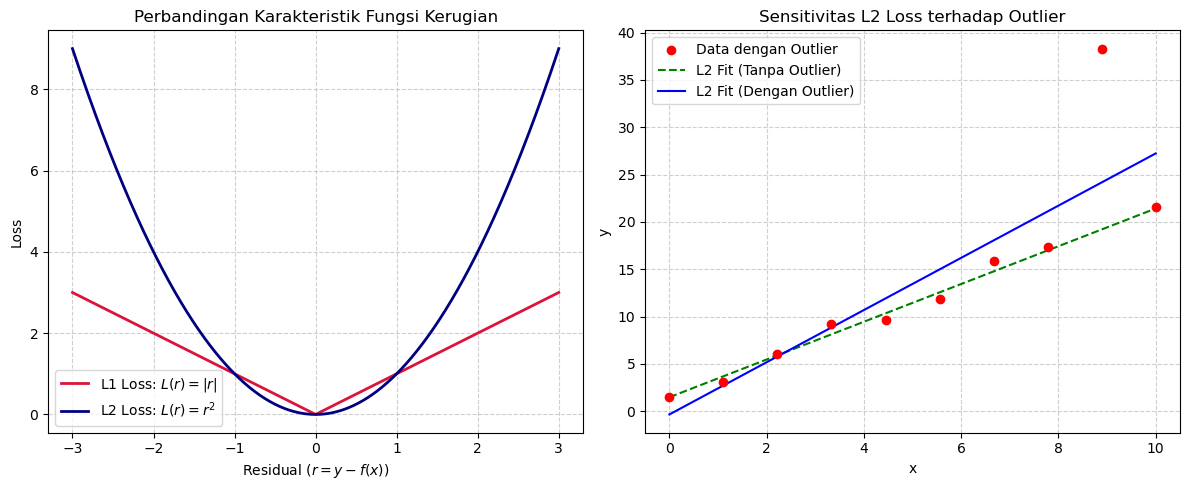

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Plot Kurva L1 Loss vs L2 Loss berdasarkan Residual
residual = np.linspace(-3, 3, 500)
l1_loss = np.abs(residual)
l2_loss = residual**2

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(residual, l1_loss, label=r'L1 Loss: $L(r) = |r|$', color='crimson', linewidth=2)
plt.plot(residual, l2_loss, label=r'L2 Loss: $L(r) = r^2$', color='navy', linewidth=2)
plt.title('Perbandingan Karakteristik Fungsi Kerugian')
plt.xlabel('Residual ($r = y - f(x)$)')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# 2. Simulasi Pengaruh Outlier terhadap Model L2 (OLS)
np.random.seed(42)
x_data = np.linspace(0, 10, 10)
y_data = 2 * x_data + 1 + np.random.normal(0, 1, 10)

# Menambahkan Outlier Ekstrem
y_data_outlier = y_data.copy()
y_data_outlier[8] += 20

# Regresi L2 dengan Outlier
X_mat = np.vstack([np.ones_like(x_data), x_data]).T
theta_clean = np.linalg.inv(X_mat.T @ X_mat) @ X_mat.T @ y_data
theta_outlier = np.linalg.inv(X_mat.T @ X_mat) @ X_mat.T @ y_data_outlier

x_grid = np.linspace(0, 10, 100)

plt.subplot(1, 2, 2)
plt.scatter(x_data, y_data_outlier, color='red', label='Data dengan Outlier', zorder=5)
plt.plot(x_grid, theta_clean[0] + theta_clean[1] * x_grid, 'g--', label='L2 Fit (Tanpa Outlier)')
plt.plot(x_grid, theta_outlier[0] + theta_outlier[1] * x_grid, 'b-', label='L2 Fit (Dengan Outlier)')
plt.title('Sensitivitas L2 Loss terhadap Outlier')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

# **BAB 2 : ESTIMATOR ORDINARY LEAST SQUARES (OLS) & DERIVASI ANALITIS**

## 2.1. Estimator Ordinary Least Squares (OLS)
Ordinary Least Squares (OLS) merupakan solusi analitis untuk mencari parameter $\theta$ optimal pada regresi linear dengan L2 loss[cite: 1, 3, 5]. Risiko empiris yang diminimalkan setara dengan *Sum of Squared Errors* (SSE)[cite: 3, 5]:
$$\mathcal{R}_{emp}(\theta) = \sum_{i=1}^n (y^{(i)} - \theta^\top x^{(i)})^2 = \|y - X\theta\|_2^2$$

Solusi penaksir OLS diperoleh dengan menyelesaikan Persamaan Normal (*Normal Equations*)[cite: 3, 5]:
$$\hat{\theta} = (X^\top X)^{-1} X^\top y$$

## 2.2. Pembuktian / Derivasi Analitis Solusi OLS
Berikut adalah derivasi matematis lengkap untuk menemukan nilai $\hat{\theta}$ yang meminimalkan $\mathcal{R}_{emp}(\theta)$ menggunakan notasi matriks[cite: 5]:

1. **Formulasi Risiko Empiris dalam Notasi Vektor/Matriks**[cite: 5]:
   $$\mathcal{R}_{emp}(\theta) = (y - X\theta)^\top (y - X\theta)$$

2. **Ekspansi Perkalian Matriks**[cite: 5]:
   $$\mathcal{R}_{emp}(\theta) = y^\top y - y^\top X \theta - \theta^\top X^\top y + \theta^\top X^\top X \theta$$
   Karena $y^\top X \theta$ bernilai skalar, maka $(y^\top X \theta)^\top = \theta^\top X^\top y$. Persamaan menjadi[cite: 5]:
   $$\mathcal{R}_{emp}(\theta) = y^\top y - 2 \theta^\top X^\top y + \theta^\top X^\top X \theta$$

3. **Menghitung Turunan Parsial terhadap $\theta$**[cite: 5]:
   Aturan diferensiasi matriks:
   * $\frac{\partial (\theta^\top A)}{\partial \theta} = A$
   * $\frac{\partial (\theta^\top B \theta)}{\partial \theta} = 2 B \theta$ (apabila $B$ simetris)

   Diturunkan terhadap $\theta$[cite: 5]:
   $$\frac{\partial \mathcal{R}_{emp}(\theta)}{\partial \theta} = -2 X^\top y + 2 X^\top X \theta$$

4. **Menyamakan Turunan dengan Nol untuk Mencari Titik Stasioner**[cite: 5]:
   $$0 = -2 X^\top y + 2 X^\top X \theta$$
   $$X^\top X \theta = X^\top y$$

5. **Mengkalikan dengan Invers $(X^\top X)^{-1}$**[cite: 5]:
   $$\hat{\theta} = (X^\top X)^{-1} X^\top y$$

## 2.3. Asumsi Statistik OLS
Agar estimator OLS bersifat *Best Linear Unbiased Estimator* (BLUE), beberapa asumsi statistik harus dipenuhi[cite: 3]:
* Galat berdistribusi normal homoskedastik: $y \mid X \sim \mathcal{N}(X\theta, \sigma^2 I)$[cite: 3].
* Tidak terdapat multikolinearitas sempurna antar fitur[cite: 3].
* Metrik evaluasi kebaikan suaian (*Goodness-of-Fit*) dirumuskan dengan $R^2$[cite: 3]:
  $$R^2 = 1 - \frac{\text{SSE}}{\text{SST}} = 1 - \frac{\sum (y^{(i)} - \hat{y}^{(i)})^2}{\sum (y^{(i)} - \bar{y})^2}$$

## 2.4. Contoh Soal & Pembahasan

**Soal:**
Diberikan himpunan data kecil:
$X_{raw} = \begin{pmatrix} 1 \\ 2 \\ 3 \end{pmatrix}$, $y = \begin{pmatrix} 3 \\ 5 \\ 7 \end{pmatrix}$

Hitung koefisien parameter $\hat{\theta} = (\theta_0, \theta_1)^\top$ menggunakan rumus OLS secara manual.

**Langkah Pembahasan:**

1. **Bentuk Design Matrix $X$ dengan menyisipkan kolom bernilai 1**[cite: 3]:
   $$X = \begin{pmatrix} 1 & 1 \\ 1 & 2 \\ 1 & 3 \end{pmatrix}$$

2. **Hitung $X^\top X$**:
   $$X^\top X = \begin{pmatrix} 1 & 1 & 1 \\ 1 & 2 & 3 \end{pmatrix} \begin{pmatrix} 1 & 1 \\ 1 & 2 \\ 1 & 3 \end{pmatrix} = \begin{pmatrix} 3 & 6 \\ 6 & 14 \end{pmatrix}$$

3. **Hitung Invers $(X^\top X)^{-1}$**:
   Determinant $|X^\top X| = (3)(14) - (6)(6) = 42 - 36 = 6$.
   $$(X^\top X)^{-1} = \frac{1}{6} \begin{pmatrix} 14 & -6 \\ -6 & 3 \end{pmatrix}$$

4. **Hitung $X^\top y$**:
   $$X^\top y = \begin{pmatrix} 1 & 1 & 1 \\ 1 & 2 & 3 \end{pmatrix} \begin{pmatrix} 3 \\ 5 \\ 7 \end{pmatrix} = \begin{pmatrix} 3 + 5 + 7 \\ 3 + 10 + 21 \end{pmatrix} = \begin{pmatrix} 15 \\ 34 \end{pmatrix}$$

5. **Hitung Solusi $\hat{\theta} = (X^\top X)^{-1} X^\top y$**:
   $$\hat{\theta} = \frac{1}{6} \begin{pmatrix} 14 & -6 \\ -6 & 3 \end{pmatrix} \begin{pmatrix} 15 \\ 34 \end{pmatrix} = \frac{1}{6} \begin{pmatrix} 14(15) - 6(34) \\ -6(15) + 3(34) \end{pmatrix} = \frac{1}{6} \begin{pmatrix} 210 - 204 \\ -90 + 102 \end{pmatrix} = \frac{1}{6} \begin{pmatrix} 6 \\ 12 \end{pmatrix} = \begin{pmatrix} 1 \\ 2 \end{pmatrix}$$

Sehingga diperoleh $\theta_0 = 1$ dan $\theta_1 = 2$, atau persamaan regresi $\hat{y} = 1 + 2x$.

In [2]:
import sympy as sp
import numpy as np

# 1. Verifikasi Derivasi OLS secara Simbolik dengan SymPy
theta0, theta1 = sp.symbols('theta_0 theta_1')
x1, x2, x3 = sp.symbols('x_1 x_2 x_3')
y1, y2, y3 = sp.symbols('y_1 y_2 y_3')

# Konstruksi Vektor & Matriks
X_sym = sp.Matrix([[1, x1], [1, x2], [1, x3]])
y_sym = sp.Matrix([y1, y2, y3])
theta_sym = sp.Matrix([theta0, theta1])

# Menghitung Persamaan Normal X^T * X * theta = X^T * y
XTX = X_sym.T * X_sym
XTy = X_sym.T * y_sym
theta_ols_sym = XTX.inv() * XTy

print("--- Solusi Simbolik OLS untuk (X^T X)^-1 X^T y ---")
sp.pprint(theta_ols_sym)

# 2. Hitung Numerik sesuai Contoh Soal
X_num = np.array([[1, 1], [1, 2], [1, 3]])
y_num = np.array([3, 5, 7])

# Menghitung theta dengan rumus matriks OLS
theta_num = np.linalg.inv(X_num.T @ X_num) @ X_num.T @ y_num

print("\n--- Hasil Perhitungan Numerik ---")
print(f"Intercept (theta_0) : {theta_num[0]:.4f}")
print(f"Slope (theta_1)     : {theta_num[1]:.4f}")

--- Solusi Simbolik OLS untuk (X^T X)^-1 X^T y ---
⎡                                                               ⎛  2     2     ↪
⎢      (-x₁ - x₂ - x₃)⋅(x₁⋅y₁ + x₂⋅y₂ + x₃⋅y₃)                  ⎝x₁  + x₂  + x ↪
⎢─────────────────────────────────────────────────── + ─────────────────────── ↪
⎢    2                           2                 2       2                   ↪
⎢2⋅x₁  - 2⋅x₁⋅x₂ - 2⋅x₁⋅x₃ + 2⋅x₂  - 2⋅x₂⋅x₃ + 2⋅x₃    2⋅x₁  - 2⋅x₁⋅x₂ - 2⋅x₁⋅ ↪
⎢                                                                              ↪
⎢          (-x₁ - x₂ - x₃)⋅(y₁ + y₂ + y₃)                           3⋅(x₁⋅y₁ + ↪
⎢─────────────────────────────────────────────────── + ─────────────────────── ↪
⎢    2                           2                 2       2                   ↪
⎣2⋅x₁  - 2⋅x₁⋅x₂ - 2⋅x₁⋅x₃ + 2⋅x₂  - 2⋅x₂⋅x₃ + 2⋅x₃    2⋅x₁  - 2⋅x₁⋅x₂ - 2⋅x₁⋅ ↪

↪  2⎞                         ⎤
↪ ₃ ⎠⋅(y₁ + y₂ + y₃)          ⎥
↪ ────────────────────────────⎥
↪          2                 2⎥
↪ x₃ + 2⋅x

# **BAB 3 : REGRESI POLINOMIAL (POLYNOMIAL REGRESSION)**

## 3.1. Fungsi Basis Polinomial
Regresi Polinomial memperluas model regresi linear sederhana untuk menangkap hubungan non-linear antara variabel independen $x$ dan variabel dependen $y$[cite: 2]. Hal ini dilakukan dengan memetakan fitur ke dalam fungsi basis polinomial berderajat $d$[cite: 2]:
$$f(x) = \theta_0 + \sum_{k=1}^d \theta_{1,k} x^k = \theta_0 + \theta_{1,1} x + \theta_{1,2} x^2 + \dots + \theta_{1,d} x^d$$

*Design Matrix* $X$ untuk regresi polinomial berderajat $d$ berukuran $n \times (d+1)$[cite: 2]:
$$X = \begin{pmatrix} 1 & x^{(1)} & (x^{(1)})^2 & \dots & (x^{(1)})^d \\ 1 & x^{(2)} & (x^{(2)})^2 & \dots & (x^{(2)})^d \\ \vdots & \vdots & \vdots & \ddots & \vdots \\ 1 & x^{(n)} & (x^{(n)})^2 & \dots & (x^{(n)})^d \end{pmatrix}$$

Meskipun model ini non-linear terhadap variabel input $x$, model ini **tetap dikategorikan sebagai model linear** karena hubungannya bersifat linear terhadap parameter $\theta$[cite: 2].

## 3.2. Kompleksitas Model dan Overfitting
Meningkatkan derajat polinomial $d$ akan meningkatkan kapasitas hipotesis model[cite: 2]. Namun, derajat yang terlalu tinggi dapat menimbulkan beberapa kendala[cite: 2]:
* **Overfitting**: Model mempelajari derau (*noise*) pada data latih, sehingga gagal melakukan generalisasi pada data baru[cite: 2].
* **Fenomena Runge (*Runge's Phenomenon*)**: Terjadi osilasi ekstrem di sekitar batas interval data ketika interpolasi polinomial derajat tinggi digunakan[cite: 2].

## 3.3. Contoh Soal & Pembahasan

**Soal:**
Diberikan 3 pasang data titik observasi: $(0, 1)$, $(1, 3)$, dan $(2, 9)$.
Bentuklah *Design Matrix* $X$ untuk regresi polinomial derajat $d = 2$, lalu tentukan vektor parameter $\theta = (\theta_0, \theta_1, \theta_2)^\top$ agar kurva melewati ketiga titik tersebut secara presisi.

**Langkah Pembahasan:**

1. **Gunakan formulasi model polinomial derajat $2$**[cite: 2]:
   $$f(x) = \theta_0 + \theta_1 x + \theta_2 x^2$$

2. **Susun sistem persamaan linear dari data masukan**:
   * Titik $(0, 1) \implies \theta_0 + \theta_1(0) + \theta_2(0)^2 = 1 \implies \theta_0 = 1$
   * Titik $(1, 3) \implies \theta_0 + \theta_1(1) + \theta_2(1)^2 = 3 \implies \theta_0 + \theta_1 + \theta_2 = 3$
   * Titik $(2, 9) \implies \theta_0 + \theta_1(2) + \theta_2(2)^2 = 9 \implies \theta_0 + 2\theta_1 + 4\theta_2 = 9$

3. **Substitusi $\theta_0 = 1$ ke dalam persamaan kedua dan ketiga**:
   * $1 + \theta_1 + \theta_2 = 3 \implies \theta_1 + \theta_2 = 2 \quad \text{--- (Persamaan A)}$
   * $1 + 2\theta_1 + 4\theta_2 = 9 \implies 2\theta_1 + 4\theta_2 = 8 \implies \theta_1 + 2\theta_2 = 4 \quad \text{--- (Persamaan B)}$

4. **Eliminasi Persamaan A dan Persamaan B**:
   $$(\theta_1 + 2\theta_2) - (\theta_1 + \theta_2) = 4 - 2$$
   $$\theta_2 = 2$$

5. **Hitung nilai $\theta_1$**:
   $$\theta_1 + 2 = 2 \implies \theta_1 = 0$$

Diperoleh vektor koefisien $\theta = \begin{pmatrix} 1 \\ 0 \\ 2 \end{pmatrix}$, sehingga fungsi polinomial yang tepat adalah $f(x) = 1 + 2x^2$.

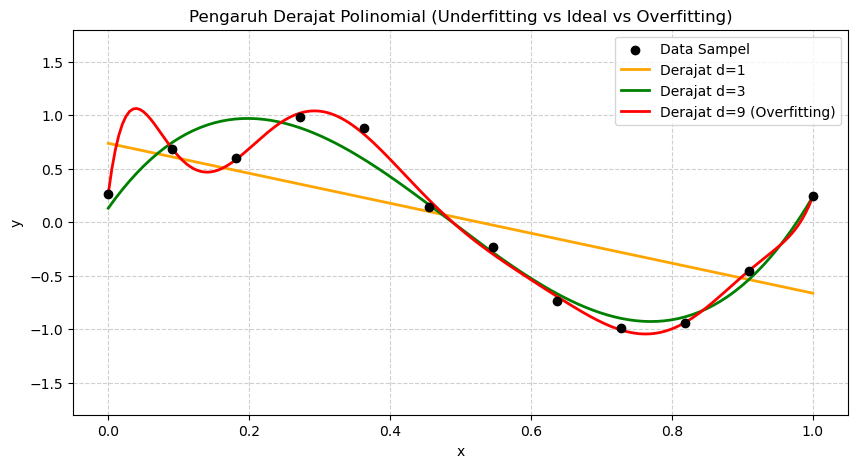

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Generasi Data dengan Noise Sesuai Fungsi Sinusoidal
np.random.seed(10)
x_sample = np.linspace(0, 1, 12)
y_sample = np.sin(2 * np.pi * x_sample) + np.random.normal(0, 0.2, 12)

x_plot = np.linspace(0, 1, 200)

plt.figure(figsize=(10, 5))
plt.scatter(x_sample, y_sample, color='black', label='Data Sampel', zorder=5)

# Fit Polinomial dengan Berbagai Derajat (d = 1, d = 3, d = 9)
degrees = [1, 3, 9]
colors = ['orange', 'green', 'red']

for deg, color in zip(degrees, colors):
    # Fit Koefisien Polinomial
    coeffs = np.polyfit(x_sample, y_sample, deg)
    poly_func = np.poly1d(coeffs)
    
    label_text = f'Derajat d={deg}' + (' (Overfitting)' if deg == 9 else '')
    plt.plot(x_plot, poly_func(x_plot), label=label_text, color=color, linewidth=2)

plt.title('Pengaruh Derajat Polinomial (Underfitting vs Ideal vs Overfitting)')
plt.xlabel('x')
plt.ylabel('y')
plt.ylim(-1.8, 1.8)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()